# 06 - Sensitivity analysis and diagnostics
Budget sensitivity (k = 5/10/20/50), performance by month, failure groups (state, category), drivers of the
model, calibration, refit vs no refit, and feature-set ablation. All on the test period with the same policy rules.

In [1]:
# Cell 1 - make the project package importable and define folders
import sys, os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ["PROJECT_ROOT"] = str(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT / "src"))
import numpy as np, pandas as pd, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 80)
from olist_risk import config
config.ensure_dirs()
print("PROJECT_ROOT =", PROJECT_ROOT)
print("outputs ->", config.OUTPUT_DIR)

PROJECT_ROOT = /workspace/ml_project2_v2
outputs -> /workspace/ml_project2_v2/outputs


In [2]:
# Cell 2 - reload test pool and scores
import json, joblib
from olist_risk import policy, metrics, models, features
ft = pd.read_pickle(config.PROCESSED_DIR / "features.pkl")
exp = json.load(open(config.OUTPUT_DIR / "experiment_configs.json")); P, R = exp["proposed_model"], exp["reference_rule"]
final = {k: joblib.load(config.MODEL_DIR / f"{k}_final.joblib") for k in ["logreg", "lgbm"]}
tp = ft[ft.split == "test"].copy()
for k, m in final.items(): tp[f"score_{k}"] = m.score(tp)
for r, f in policy.RULES.items(): tp[r] = f(tp).values
methods = {"logreg": "score_logreg", "lgbm": "score_lgbm", **{r: r for r in policy.RULES}}
print(P, R, tp.shape)

logreg rule_longest_distance (18960, 79)


late orders identified


method,lgbm,logreg,random,rule_longest_distance,rule_shortest_promise
k_per_day,,,,,
5,36.0,45.0,13.9,11.0,46.0
10,60.0,71.0,26.5,34.0,80.0
20,86.0,105.0,52.1,60.0,123.0
50,164.0,181.0,129.3,127.0,269.0


precision of investigations


method,lgbm,logreg,random,rule_longest_distance,rule_shortest_promise
k_per_day,,,,,
5,0.082,0.103,0.032,0.025,0.105
10,0.069,0.082,0.031,0.039,0.092
20,0.050,0.061,0.030,0.035,0.071
50,0.038,0.042,0.030,0.030,0.063


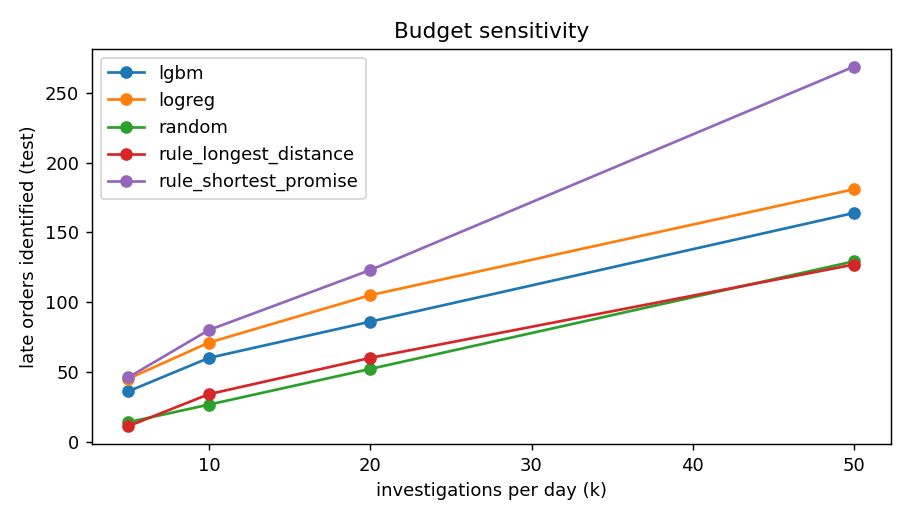

In [3]:
# Cell 3 - investigation budget sensitivity
rows = []
for k in config.BUDGETS:
    for name in ["logreg", "lgbm", R, "rule_shortest_promise"]:
        e = policy.evaluate_policy(tp, methods[name], k); rows.append({"k_per_day": k, "method": name, **e})
    rnd = policy.random_policy_expectation(tp, k, n_rep=50); rows.append({"k_per_day": k, "method": "random", **rnd})
bud = pd.DataFrame(rows)
bt = bud.pivot_table(index="k_per_day", columns="method", values="late_identified").round(1)
bp = bud.pivot_table(index="k_per_day", columns="method", values="precision").round(3)
bud.to_csv(config.TABLE_DIR / "06_budget_sensitivity.csv", index=False)
print("late orders identified"); display(bt); print("precision of investigations"); display(bp)
fig, ax = plt.subplots(figsize=(7, 4))
for c in bt.columns: ax.plot(bt.index, bt[c], marker="o", label=c)
ax.set_xlabel("investigations per day (k)"); ax.set_ylabel("late orders identified (test)"); ax.legend(); ax.set_title("Budget sensitivity")
fig.tight_layout(); fig.savefig(config.FIG_DIR / "06_budget_sensitivity.png", dpi=130); plt.close(fig); display(Image(str(config.FIG_DIR / "06_budget_sensitivity.png")))

In [4]:
# Cell 4 - performance by month of the test period (10/day)
tp["month"] = tp.order_approved_at.dt.to_period("M").astype(str)
rows = []
for mth, g in tp.groupby("month"):
    for name in [P, R]:
        e = policy.evaluate_policy(g, methods[name]); rows.append({"month": mth, "method": name, **{k: e[k] for k in
              ["pool_orders", "pool_late", "base_rate", "late_identified", "unnecessary_investigations", "precision", "recall_of_late", "lift_vs_random"]}})
    pm = metrics.predictive_metrics(g[g.label_available].is_late, g[g.label_available][methods[P]])
    rows[-2]["pr_auc"] = pm["pr_auc"]; rows[-2]["roc_auc"] = pm["roc_auc"]
mon = pd.DataFrame(rows); mon.to_csv(config.TABLE_DIR / "06_by_month.csv", index=False); display(mon.round(3))

,month,method,pool_orders,pool_late,base_rate,late_identified,unnecessary_investigations,precision,recall_of_late,lift_vs_random,pr_auc,roc_auc
0,2018-06,logreg,6164,71,0.012,13,279,0.043,0.183,3.762,0.037,0.747
1,2018-06,rule_longest_distance,6164,71,0.012,9,286,0.030,0.127,2.605,NaN,NaN
2,2018-07,logreg,6176,193,0.031,40,243,0.138,0.207,4.429,0.108,0.633
3,2018-07,rule_longest_distance,6176,193,0.031,22,263,0.076,0.114,2.436,NaN,NaN
4,2018-08,logreg,6620,408,0.062,18,257,0.064,0.044,1.043,0.069,0.507
5,2018-08,rule_longest_distance,6620,408,0.062,3,274,0.011,0.007,0.174,NaN,NaN


In [5]:
# Cell 5 - failure groups: where are late orders missed? (customer state)
s = policy.select_daily_topk(tp, methods[P])
s["hit"] = s.selected & (s.outcome_status == "late"); s["miss"] = ~s.selected & (s.outcome_status == "late")
s["false_alarm"] = s.selected & (s.outcome_status == "on_time")
grp = s.groupby("customer_state").agg(orders=("order_id", "size"), late=("miss", "sum"), hits=("hit", "sum"),
                                      selected=("selected", "sum"), false_alarms=("false_alarm", "sum"))
grp["late"] = grp.late + grp.hits; grp = grp.rename(columns={"late": "late_orders"})
grp["capture_rate"] = (grp.hits / grp.late_orders.replace(0, np.nan)).round(3)
grp["late_rate"] = (grp.late_orders / grp.orders).round(4)
grp = grp.sort_values("late_orders", ascending=False); grp.to_csv(config.TABLE_DIR / "06_failure_by_customer_state.csv")
display(grp.head(15))

,orders,late_orders,hits,selected,false_alarms,capture_rate,late_rate
customer_state,,,,,,,
SP,8786,405,11,90,78,0.027,0.0461
RJ,2179,68,18,382,353,0.265,0.0312
BA,616,27,6,50,44,0.222,0.0438
MG,2087,21,0,19,19,0.000,0.0101
RS,920,18,0,12,12,0.000,0.0196
PR,963,16,0,3,3,0.000,0.0166
PE,318,14,1,15,14,0.071,0.0440
MA,113,14,13,60,45,0.929,0.1239
ES,354,14,1,36,34,0.071,0.0395


In [6]:
# Cell 6 - failure groups by product category (top 15 by late orders)
cat = s.groupby("main_category").agg(orders=("order_id", "size"), hits=("hit", "sum"), missed=("miss", "sum"), false_alarms=("false_alarm", "sum"))
cat["late_orders"] = cat.hits + cat.missed; cat["capture_rate"] = (cat.hits / cat.late_orders.replace(0, np.nan)).round(3)
cat = cat.sort_values("late_orders", ascending=False); cat.to_csv(config.TABLE_DIR / "06_failure_by_category.csv"); display(cat.head(15))

,orders,hits,missed,false_alarms,late_orders,capture_rate
main_category,,,,,,
health_beauty,2279,32,89,185,121,0.264
housewares,1484,1,46,17,47,0.021
watches_gifts,1354,4,43,77,47,0.085
bed_bath_table,1721,11,32,125,43,0.256
computers_accessories,1131,3,32,18,35,0.086
sports_leisure,1229,3,31,30,34,0.088
auto,945,5,29,34,34,0.147
furniture_decor,974,5,29,42,34,0.147
baby,618,2,27,35,29,0.069


In [7]:
# Cell 7 - what do missed late orders look like compared with caught ones?
cmpc = ["promised_days", "distance_km", "seller_late_rate_sm", "route_late_rate_sm", "market_overdue_open", "days_late", "total_price"]
prof = pd.DataFrame({"caught (hits)": s[s.hit][cmpc].median(), "missed late": s[s.miss][cmpc].median(),
                     "false alarms": s[s.false_alarm][cmpc].median()}).round(2)
prof.to_csv(config.TABLE_DIR / "06_error_profile.csv"); display(prof)

,caught (hits),missed late,false alarms
promised_days,20.00,9.00,23.00
distance_km,1669.84,109.36,804.83
seller_late_rate_sm,0.11,0.06,0.09
route_late_rate_sm,0.15,0.04,0.15
market_overdue_open,232.00,233.00,290.00
days_late,6.00,4.00,-12.00
total_price,93.50,83.00,99.90


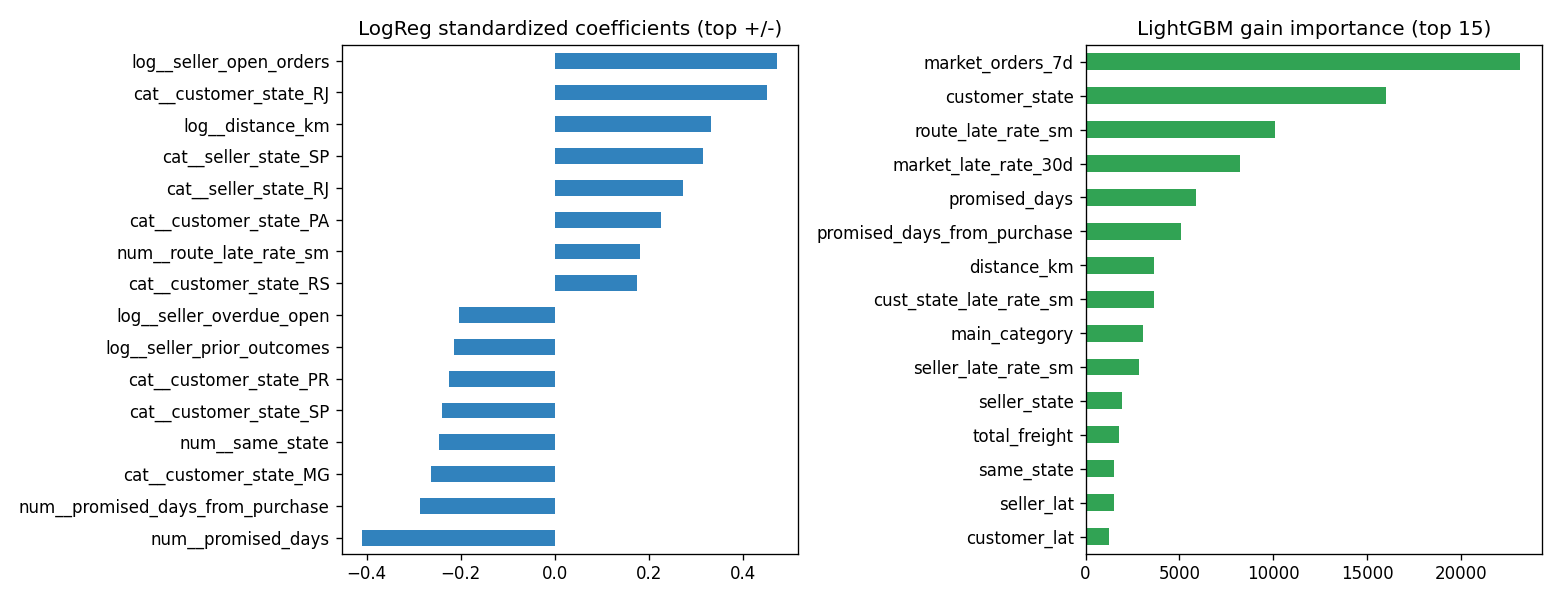

In [8]:
# Cell 8 - model drivers: logistic-regression coefficients and LightGBM gain importance
lr = final["logreg"].model
names = lr.named_steps["pre"].get_feature_names_out()
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=names).sort_values()
coef.to_csv(config.TABLE_DIR / "06_logreg_coefficients.csv")
gb = final["lgbm"].model.booster_
imp = pd.Series(gb.feature_importance("gain"), index=gb.feature_name()).sort_values(ascending=False)
imp.to_csv(config.TABLE_DIR / "06_lgbm_gain_importance.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
pd.concat([coef.head(8), coef.tail(8)]).plot(kind="barh", ax=axes[0], color="#3182bd"); axes[0].set_title("LogReg standardized coefficients (top +/-)")
imp.head(15)[::-1].plot(kind="barh", ax=axes[1], color="#31a354"); axes[1].set_title("LightGBM gain importance (top 15)")
fig.tight_layout(); fig.savefig(config.FIG_DIR / "06_model_drivers.png", dpi=120); plt.close(fig); display(Image(str(config.FIG_DIR / "06_model_drivers.png")))

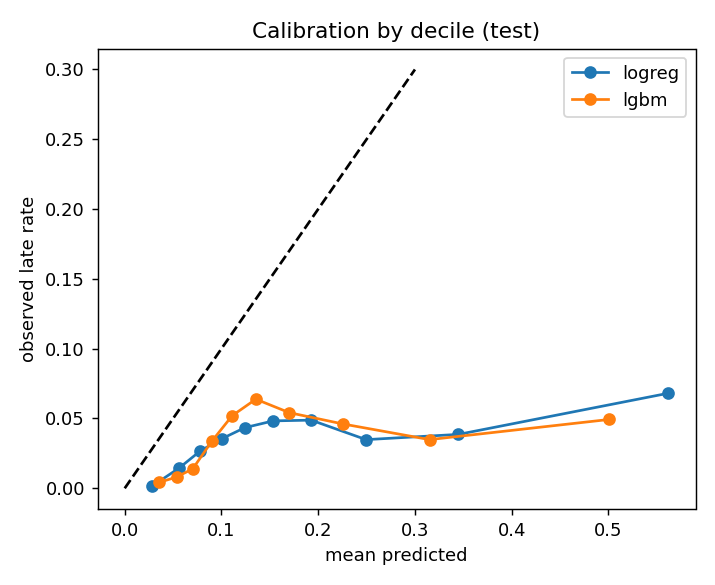

Mean predicted vs observed: {'logreg': (np.float64(0.189), np.float64(0.036)), 'lgbm': (np.float64(0.1708), np.float64(0.036))}


In [9]:
# Cell 9 - calibration of the predicted probabilities (labelled test orders)
tl = tp[tp.label_available]
fig, ax = plt.subplots(figsize=(5.5, 4.5)); rows = []
for k in ["logreg", "lgbm"]:
    q = pd.qcut(tl[f"score_{k}"].rank(method="first"), 10, labels=False)
    c = tl.groupby(q).agg(pred=(f"score_{k}", "mean"), obs=("is_late", "mean")); ax.plot(c.pred, c.obs, marker="o", label=k)
    rows.append(c.assign(model=k))
ax.plot([0, .3], [0, .3], "k--"); ax.set_xlabel("mean predicted"); ax.set_ylabel("observed late rate"); ax.legend(); ax.set_title("Calibration by decile (test)")
fig.tight_layout(); fig.savefig(config.FIG_DIR / "06_calibration.png", dpi=130); plt.close(fig); display(Image(str(config.FIG_DIR / "06_calibration.png")))
pd.concat(rows).to_csv(config.TABLE_DIR / "06_calibration.csv")
print("Mean predicted vs observed:", {k: (round(tl[f'score_{k}'].mean(), 4), round(tl.is_late.mean(), 4)) for k in ["logreg", "lgbm"]})

In [10]:
# Cell 10 - refit on train+validation vs the validation-period model (no refit)
rows = []
for k in ["logreg", "lgbm"]:
    m0 = joblib.load(config.MODEL_DIR / f"{k}_trainonly.joblib"); tp["_s0"] = m0.score(tp)
    for lbl, col in [("trained on train only", "_s0"), ("refit on train+validation (used)", f"score_{k}")]:
        e = policy.evaluate_policy(tp, col); pm = metrics.predictive_metrics(tl.is_late, tp.loc[tl.index, col])
        rows.append({"model": k, "version": lbl, "late_identified": e["late_identified"], "precision": e["precision"], "pr_auc": pm["pr_auc"], "roc_auc": pm["roc_auc"]})
rf = pd.DataFrame(rows); rf.to_csv(config.TABLE_DIR / "06_refit_vs_trainonly.csv", index=False); display(rf.round(4))

,model,version,late_identified,precision,pr_auc,roc_auc
0,logreg,trained on train only,62,0.0713,0.0655,0.6442
1,logreg,refit on train+validation (used),71,0.0817,0.0674,0.6250
2,lgbm,trained on train only,56,0.0644,0.0645,0.6586
3,lgbm,refit on train+validation (used),60,0.0690,0.0511,0.6207


In [11]:
# Cell 11 - feature-group ablation for the proposed model family (refit on train+validation, test)
trainval = ft[ft.trainval_eligible]; ytv = trainval.is_late.astype(int)
params = exp["selected"][P]["params"]
groups = {"all features": features.NUM_FEATURES,
          "no history features": [c for c in features.NUM_FEATURES if c not in features.HISTORY_FEATURES],
          "no market-level features": [c for c in features.NUM_FEATURES if not c.startswith("market_")],
          "history features only": features.HISTORY_FEATURES}
rows = []
for g, cols in groups.items():
    m = models.FittedModel(P, params, num_features=cols).fit(trainval, ytv); tp["_a"] = m.score(tp)
    e = policy.evaluate_policy(tp, "_a"); pm = metrics.predictive_metrics(tl.is_late, tp.loc[tl.index, "_a"])
    rows.append({"feature_group": g, "n_numeric": len(cols), "late_identified": e["late_identified"], "precision": e["precision"], "pr_auc": pm["pr_auc"], "roc_auc": pm["roc_auc"]})
abl = pd.DataFrame(rows); abl.to_csv(config.TABLE_DIR / "06_ablation.csv", index=False); display(abl.round(4))
print("(diagnostic only - the test set was NOT used to choose the model)")

,feature_group,n_numeric,late_identified,precision,pr_auc,roc_auc
0,all features,45,66,0.0759,0.0679,0.6730
1,no history features,31,69,0.0794,0.0678,0.6545
2,no market-level features,42,71,0.0817,0.0674,0.6250
3,history features only,14,31,0.0357,0.0444,0.5996


(diagnostic only - the test set was NOT used to choose the model)


In [12]:
# Cell 12 - investigate fewer than 10 when risk is low? precision of the daily rank positions
s = policy.select_daily_topk(tp, methods[P])
byrank = s[s.daily_rank <= 20].groupby("daily_rank").apply(lambda g: pd.Series({"orders": len(g), "late_rate": (g.outcome_status == "late").mean(),
                                                     "mean_score": g[methods[P]].mean()}), include_groups=False).round(4)
byrank.to_csv(config.TABLE_DIR / "06_precision_by_daily_rank.csv"); display(byrank.T)

daily_rank,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
orders,88.0000,88.0000,88.0000,88.0000,87.0000,86.0000,86.0000,86.0000,86.0000,86.0000,86.0000,86.0000,86.0000,86.0000,86.0000,85.0000,85.0000,85.0000,85.0000,85.0000
late_rate,0.1364,0.1250,0.0568,0.1023,0.0920,0.0698,0.0349,0.0698,0.0349,0.0930,0.0000,0.0581,0.0698,0.0814,0.0116,0.0353,0.0471,0.0588,0.0118,0.0235
mean_score,0.7352,0.6717,0.6378,0.6102,0.5906,0.5761,0.5567,0.5367,0.5190,0.5024,0.4885,0.4747,0.4628,0.4478,0.4369,0.4335,0.4248,0.4161,0.4075,0.4004


## Post-hoc analysis (added AFTER the final test evaluation - not a valid test estimate)
The final test showed that the rule chosen on validation (longest distance) collapsed, while the shortest-promise rule
(worst on validation) did best. That suggested a feature the pre-specified model lacked: **delivery slack** = promised days
minus the typical delivery time on the same route (learned only from orders delivered before approval). The cell below
checks this idea on validation first and then on test. Because the idea came from looking at test results, these numbers
are exploratory and are reported separately from the main results.

In [13]:
# Cell 13 - post-hoc: slack features (validation first, then test)
train = ft[ft.train_eligible]; ytr = train.is_late.astype(int)
vp = ft[ft.split == "validation"].copy()
rows = []
for kind in ["logreg", "lgbm"]:
    prm = exp["selected"][kind]["params"]
    base_cols = models.FEATURE_SETS[exp["selected"][kind]["feature_set"]]
    for lbl, cols in [("selected feature set", base_cols), ("selected feature set + slack features (post-hoc)", base_cols + features.POSTHOC_FEATURES)]:
        mv = models.FittedModel(kind, prm, num_features=cols).fit(train, ytr); vp["_p"] = mv.score(vp)
        mt = models.FittedModel(kind, prm, num_features=cols).fit(trainval, ytv); tp["_p"] = mt.score(tp)
        rows.append({"model": kind, "features": lbl, "val_late_identified": policy.evaluate_policy(vp, "_p")["late_identified"],
                     "test_late_identified": policy.evaluate_policy(tp, "_p")["late_identified"],
                     "test_pr_auc": metrics.predictive_metrics(tl.is_late, tp.loc[tl.index, "_p"])["pr_auc"]})
for df_, nm in [(vp, "val"), (tp, "test")]:
    df_["_slack"] = -df_["slack_vs_route"].fillna(df_["slack_vs_route"].median())
rows.append({"model": "rule_smallest_route_slack", "features": "non-ML rule (post-hoc)", "val_late_identified": policy.evaluate_policy(vp, "_slack")["late_identified"],
             "test_late_identified": policy.evaluate_policy(tp, "_slack")["late_identified"],
             "test_pr_auc": metrics.predictive_metrics(tl.is_late, tp.loc[tl.index, "_slack"], False)["pr_auc"]})
ph = pd.DataFrame(rows); ph.to_csv(config.TABLE_DIR / "06_posthoc_slack_features.csv", index=False); display(ph.round(4))
print("POST-HOC / test-informed: use as a hypothesis for the next model version, not as the reported test result.")

,model,features,val_late_identified,test_late_identified,test_pr_auc
0,logreg,selected feature set,255,71,0.0674
1,logreg,selected feature set + slack features (post-hoc),250,72,0.0678
2,lgbm,selected feature set,227,60,0.0511
3,lgbm,selected feature set + slack features (post-hoc),239,48,0.0513
4,rule_smallest_route_slack,non-ML rule (post-hoc),116,73,0.1350


POST-HOC / test-informed: use as a hypothesis for the next model version, not as the reported test result.


In [14]:
# Cell 14 - summary of all saved outputs
for p in sorted(config.OUTPUT_DIR.rglob("*")):
    if p.is_file(): print(f"{str(p.relative_to(config.OUTPUT_DIR)):55s} {p.stat().st_size/1024:8.1f} KB")

daily_prioritization_test.csv                              208.2 KB
daily_prioritization_test_rule.csv                          82.0 KB
experiment_configs.json                                      5.4 KB
figures/01_monthly_volume_late_rate.png                     64.6 KB
figures/01_promised_vs_actual_days.png                      40.8 KB
figures/02_days_late_hist.png                               22.1 KB
figures/03_late_rate_by_decile.png                         138.5 KB
figures/05_cumulative_hits_test.png                         70.7 KB
figures/05_pr_curves_test.png                               46.0 KB
figures/06_budget_sensitivity.png                           68.3 KB
figures/06_calibration.png                                  42.5 KB
figures/06_model_drivers.png                               116.2 KB
models/lgbm_final.joblib                                   196.7 KB
models/lgbm_trainonly.joblib                               196.5 KB
models/logreg_final.joblib                      